# Random Forest: Cafeteria

**Laboratorio 3 - Ruta Alpes.**

Se desarrollo el modelo con el CSV compartido y siguiendo la [practica del curso](../MaterialDeClase-ISIS-2611/202620/Pr%C3%A1cticas/P10_Ensembles/P10_RandomForest.ipynb). La limpieza se documenta en procesamiento_datos.ipynb.

**Pregunta:** que caracteristicas del conductor y del trayecto ayudan a predecir la aceptacion del cupon de Cafeteria?


## 1. Importacion de librerias


In [1]:
from pathlib import Path
import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import sklearn
from IPython.display import display

from sklearn.model_selection import train_test_split, StratifiedKFold, GridSearchCV
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.base import clone
from sklearn.metrics import (classification_report, confusion_matrix, ConfusionMatrixDisplay,
                             precision_score, recall_score, f1_score)


In [2]:
from sklearn.ensemble import RandomForestClassifier


## 2. Carga de los datos

Ejecutar desde la raiz de LABORATORIO-3-AM. El CSV debe conservar id_fila, cupon y acepta_cupon en Si/No.
Puede contener faltantes en predictores: se imputan dentro del pipeline. Los faltantes de la etiqueta no se imputan.


In [3]:
CUPON = 'Cafetería'
ALGORITMO = 'bosque_aleatorio'
SEMILLA = 42
N_FOLDS = 5
N_JOBS = -1
RUTA_DATOS = Path('data/procesados/datos_limpios.csv')
RUTA_RESULTADOS = Path('resultados') / 'cafeteria_bosque_aleatorio'



COLUMNAS_EXCLUIR = []
COLUMNAS_NUMERICAS = ['temperatura']

if not RUTA_DATOS.exists():
    raise FileNotFoundError('Falta data/procesados/datos_limpios.csv. Preparar el CSV y abrir desde la raíz del laboratorio.')
datos = pd.read_csv(RUTA_DATOS)


In [4]:
requeridas = {'id_fila', 'cupon', 'acepta_cupon'}
if not requeridas.issubset(datos.columns):
    raise ValueError(f'Faltan columnas: {requeridas - set(datos.columns)}')
if datos['id_fila'].isna().any() or not datos['id_fila'].is_unique:
    raise ValueError('id_fila debe ser único y no tener faltantes.')
data = datos.loc[datos['cupon'].eq(CUPON)].copy()
data = data.sort_values('id_fila').set_index('id_fila')
if data.empty:
    raise ValueError(f'No se encontraron filas de {CUPON}. Revisar las categorías del CSV.')
if data['acepta_cupon'].isna().any() or not set(data['acepta_cupon']).issubset({'Sí', 'No'}):
    raise ValueError('acepta_cupon debe contener solamente Sí y No, sin faltantes.')
data.head()


,destino,acompanante,clima,temperatura,hora,cupon,vigencia_cupon,genero,edad,estado_civil,...,ingreso,frecuencia_bar,frecuencia_cafeteria,frecuencia_comida_para_llevar,frecuencia_restaurante_menos_20,frecuencia_restaurante_20_a_50,tiempo_cupon_mayor_15min,tiempo_cupon_mayor_25min,misma_direccion,acepta_cupon
id_fila,,,,,,,,,,,,,,,,,,,,,
1,Sin lugar urgente,Amigo(s),Soleado,80,10:00 a.m.,Cafetería,2 horas,Femenino,21,Unión libre,...,$37.500 - $49.999,nunca,nunca,NaN,4 a 8,1 a 3,No,No,No,No
3,Sin lugar urgente,Amigo(s),Soleado,80,2:00 p.m.,Cafetería,2 horas,Femenino,21,Unión libre,...,$37.500 - $49.999,nunca,nunca,NaN,4 a 8,1 a 3,Sí,No,No,No
4,Sin lugar urgente,Amigo(s),Soleado,80,2:00 p.m.,Cafetería,1 día,Femenino,21,Unión libre,...,$37.500 - $49.999,nunca,nunca,NaN,4 a 8,1 a 3,Sí,No,No,No
12,Sin lugar urgente,Hijo(s),Soleado,55,6:00 p.m.,Cafetería,2 horas,Femenino,21,Unión libre,...,$37.500 - $49.999,nunca,nunca,NaN,4 a 8,1 a 3,Sí,No,No,Sí
15,Casa,Solo,Soleado,80,6:00 p.m.,Cafetería,2 horas,Femenino,21,Unión libre,...,$37.500 - $49.999,nunca,nunca,NaN,4 a 8,1 a 3,No,No,No,No


## 3. Revision del subconjunto

La exploracion completa y las correcciones pertenecen al notebook de limpieza. Aqui comprobamos que datos llegan al modelo.


In [5]:
data.shape


(3979, 23)

In [6]:
data.isna().sum()


destino                             0
acompanante                         0
clima                               0
temperatura                         0
hora                                0
cupon                               0
vigencia_cupon                      0
genero                              0
edad                                0
estado_civil                        0
tiene_hijos                         0
educacion                           0
ocupacion                           0
ingreso                             0
frecuencia_bar                     37
frecuencia_cafeteria               72
frecuencia_comida_para_llevar      57
frecuencia_restaurante_menos_20    50
frecuencia_restaurante_20_a_50     55
tiempo_cupon_mayor_15min            0
tiempo_cupon_mayor_25min            0
misma_direccion                     0
acepta_cupon                        0
dtype: int64

In [7]:
data['acepta_cupon'].value_counts()


No    1996
Sí    1983
Name: acepta_cupon, dtype: int64

Cafeteria tiene 3.979 registros: 1.996 rechazos y 1.983 aceptaciones, cerca de la mitad por clase. No se aplico balanceo en este caso.

En la limpieza se eliminaron vehiculo por su alta proporcion de nulos, tiempo_cupon_mayor_5min por ser constante y direccion_opuesta por repetir la informacion de misma_direccion. Se conservaron los nulos de frecuencia para imputarlos con la moda dentro de cada fold. id_fila solo identifica registros y cupon se excluye al ser constante en este subconjunto.

Quedaron 21 predictores, 3.183 filas de entrenamiento y 796 de test. Los tres algoritmos usan exactamente las mismas filas y particiones.


## 4. Particion de los datos

Si se representa con 1 y No con 0. Excluimos cupon, que es constante, y la etiqueta de los predictores. id_fila quedo como indice.
La semilla, la fraccion de test y los folds deben ser iguales para los tres modelos del mismo cupon.


In [8]:
X = data.drop(columns=['acepta_cupon', 'cupon', *COLUMNAS_EXCLUIR])
y = data['acepta_cupon'].map({'No': 0, 'Sí': 1}).astype(int)
numericas_features = [c for c in COLUMNAS_NUMERICAS if c in X.columns]
categoricas_features = [c for c in X.columns if c not in numericas_features]



for columna in categoricas_features:
    X[columna] = X[columna].astype('string').astype(object)
    X[columna] = X[columna].where(X[columna].notna(), np.nan)
for columna in numericas_features:
    X[columna] = pd.to_numeric(X[columna], errors='raise')
    if not np.isfinite(X[columna].dropna().to_numpy()).all():
        raise ValueError(f'Hay valores no finitos en {columna}. Revisar la limpieza.')

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=SEMILLA, stratify=y
)
if y_train.nunique() != 2 or y_train.value_counts().min() < N_FOLDS:
    raise ValueError('Se requieren ambas clases y suficientes ejemplos para cinco folds.')
if numericas_features and X_train[numericas_features].isna().all().any():
    raise ValueError('Hay columnas numéricas completamente vacías en train. Revisar si deben excluirse.')
clase_minoritaria = int(y_train.value_counts().idxmin())
kfold = StratifiedKFold(n_splits=N_FOLDS, shuffle=True, random_state=SEMILLA)
print('Train:', X_train.shape, '| Test:', X_test.shape)
print('Clase minoritaria en train:', {0: 'No', 1: 'Sí'}[clase_minoritaria])


Train: (3183, 21) | Test: (796, 21)
Clase minoritaria en train: Sí


## 5. Construccion del pipeline

Seguimos el esquema de SimpleImputer y ColumnTransformer de la practica 7. 
La mediana numerica y la moda de cada variable categorica se calculan dentro de cada fold de entrenamiento.


El arbol y el bosque no necesitan escalamiento; conservamos la escala numerica original.


In [9]:
numerica_transformer = Pipeline(steps=[
    ('imputador', SimpleImputer(strategy='median')),
])


Codificamos las categorias con OneHotEncoder(handle_unknown='ignore'), como en la practica de arboles.


In [10]:
categorica_transformer = Pipeline(steps=[
    ('imputador', SimpleImputer(strategy='most_frequent')),
    ('onehot', OneHotEncoder(handle_unknown='ignore')),
])


In [11]:
preprocesador = ColumnTransformer(transformers=[
    ('num', numerica_transformer, numericas_features),
    ('cat', categorica_transformer, categoricas_features),
])


In [12]:
rf_pipeline = Pipeline(steps=[
    ('preprocesador', preprocesador),
    ('modelo', RandomForestClassifier(random_state=SEMILLA, n_jobs=1)),
])


## 6. Busqueda de hiperparametros

Usamos GridSearchCV de forma explicita, como en las practicas. Se selecciona por F1 macro en CV, dando igual peso a ambas clases. La practica 7 usa F1 binario; unificamos F1 macro con las practicas 8-10 para comparar los tres algoritmos. Tambien reportamos el F1 de aceptacion.


Usamos los valores de la grilla de la practica 10. Alli el bosque recibe datos numericos sin pipeline; aqui anadimos el preprocesamiento porque hay categorias y el laboratorio exige pipeline. Por eso los parametros llevan el prefijo modelo__.


In [13]:
param_grid = {
    'modelo__n_estimators': [100, 200, 300],
    'modelo__max_depth': [4, 6, 10],
    'modelo__min_samples_leaf': [1, 3, 5],
}


In [14]:
rf_grid = GridSearchCV(
    estimator=rf_pipeline, param_grid=param_grid,
    cv=kfold, scoring='f1_macro', n_jobs=N_JOBS,
    return_train_score=True, error_score='raise',
)
rf_grid.fit(X_train, y_train)


GridSearchCV(cv=StratifiedKFold(n_splits=5, random_state=42, shuffle=True),
             error_score='raise',
             estimator=Pipeline(steps=[('preprocesador',
                                        ColumnTransformer(transformers=[('num',
                                                                         Pipeline(steps=[('imputador',
                                                                                          SimpleImputer(strategy='median'))]),
                                                                         ['temperatura']),
                                                                        ('cat',
                                                                         Pipeline(steps=[('imputador',
                                                                                          SimpleImputer(strategy='most_frequent')),
                                                                                         ('onehot',
                                                                                          OneHot...
                                                                          'frecuencia_restaurante_menos_20',
                                                                          'frecuencia_restaurante_20_a_50',
                                                                          'tiempo_cupon_mayor_15min',
                                                                          'tiempo_cupon_mayor_25min',
                                                                          'misma_direccion'])])),
                                       ('modelo',
                                        RandomForestClassifier(n_jobs=1,
                                                               random_state=42))]),
             n_jobs=-1,
             param_grid={'modelo__max_depth': [4, 6, 10],
                         'modelo__min_samples_leaf': [1, 3, 5],
                         'modelo__n_estimators': [100, 200, 300]},
             return_train_score=True, scoring='f1_macro')

In [15]:
print('Mejores hiperparámetros:', rf_grid.best_params_)
print('F1 macro promedio en CV:', rf_grid.best_score_)
resultados_cv = pd.DataFrame(rf_grid.cv_results_)
columnas_cv = [c for c in resultados_cv.columns if c.startswith('param_')]
columnas_cv += ['mean_train_score', 'mean_test_score', 'std_test_score', 'rank_test_score']
display(resultados_cv[columnas_cv].sort_values('rank_test_score').head(10))
mejor_modelo = rf_grid.best_estimator_
variante_elegida = 'sin_balanceo'


Mejores hiperparámetros: {'modelo__max_depth': 10, 'modelo__min_samples_leaf': 1, 'modelo__n_estimators': 100}
F1 macro promedio en CV: 0.7482458244885299


,param_modelo__max_depth,param_modelo__min_samples_leaf,param_modelo__n_estimators,mean_train_score,mean_test_score,std_test_score,rank_test_score
18,10,1,100,0.901505,0.748246,0.015203,1
19,10,1,200,0.901419,0.744121,0.015439,2
20,10,1,300,0.901576,0.743820,0.014102,3
21,10,3,100,0.836922,0.738801,0.014746,4
23,10,3,300,0.836531,0.736846,0.016220,5
22,10,3,200,0.837397,0.736538,0.015497,6
25,10,5,200,0.805267,0.727397,0.015078,7
24,10,5,100,0.807074,0.725857,0.015596,8
26,10,5,300,0.803775,0.723664,0.014915,9
16,6,5,200,0.750734,0.721091,0.013882,10


La mejor configuracion uso 100 arboles, profundidad maxima de 10 y minimo de una muestra por hoja. Fue la combinacion con mayor F1 macro de validacion dentro de la grilla probada; aumentar a 200 o 300 arboles no produjo una configuracion ganadora.

El F1 macro promedio fue 0.9015 en entrenamiento de los folds y 0.7482 en validacion, con desviacion de 0.0152 entre folds. La diferencia de 0.1533 indica sobreajuste: el bosque se adapta mucho mejor a las filas usadas para entrenar. Aunque lidera la validacion, esa brecha limita la confianza en su generalizacion.


## 7. Evaluacion

Como en las practicas, revisamos reporte de clasificacion y matriz de confusion. Test conserva su distribucion original y no se usa para ajustar parametros ni escoger la variante.


              precision    recall  f1-score   support

          No       0.73      0.71      0.72       399
          Sí       0.72      0.74      0.73       397

    accuracy                           0.72       796
   macro avg       0.73      0.72      0.72       796
weighted avg       0.73      0.72      0.72       796

[[282 117]
 [102 295]]


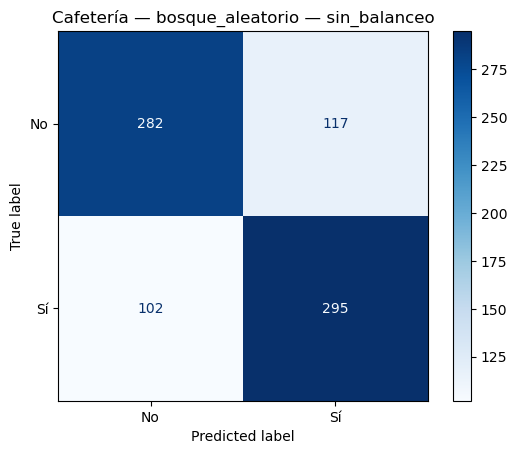

In [16]:
y_pred = mejor_modelo.predict(X_test)
print(classification_report(y_test, y_pred, labels=[0, 1], target_names=['No', 'Sí'], zero_division=0))
print(confusion_matrix(y_test, y_pred, labels=[0, 1]))
ConfusionMatrixDisplay.from_predictions(
    y_test, y_pred, labels=[0, 1], display_labels=['No', 'Sí'], cmap='Blues'
)
plt.title(f'{CUPON} — {ALGORITMO} — {variante_elegida}')
plt.show()


In [17]:
def metricas_modelo(y_true, y_pred):
    return {
        'precision_si': precision_score(y_true, y_pred, pos_label=1, zero_division=0),
        'recall_si': recall_score(y_true, y_pred, pos_label=1, zero_division=0),
        'f1_si': f1_score(y_true, y_pred, pos_label=1, zero_division=0),
        'f1_macro': f1_score(y_true, y_pred, average='macro', zero_division=0),
        'recall_minoritaria': recall_score(y_true, y_pred, pos_label=clase_minoritaria, zero_division=0),
    }

comparacion_train_test = pd.DataFrame({
    'train': metricas_modelo(y_train, mejor_modelo.predict(X_train)),
    'test': metricas_modelo(y_test, y_pred),
}).T
display(comparacion_train_test.round(3))


,precision_si,recall_si,f1_si,f1_macro,recall_minoritaria
train,0.863,0.898,0.880,0.878,0.898
test,0.716,0.743,0.729,0.725,0.743


In [18]:
pred_sin_balanceo = rf_grid.best_estimator_.predict(X_test)
resultados = pd.DataFrame([{
    'cupon': CUPON, 'algoritmo': ALGORITMO, 'variante': 'sin_balanceo',
    'elegida_por_cv': variante_elegida == 'sin_balanceo',
    'f1_macro_cv': rf_grid.best_score_, 'clase_minoritaria': clase_minoritaria,
    **metricas_modelo(y_test, pred_sin_balanceo),
}])


In [19]:
display(resultados.round(3))


,cupon,algoritmo,variante,elegida_por_cv,f1_macro_cv,clase_minoritaria,precision_si,recall_si,f1_si,f1_macro,recall_minoritaria
0,Cafetería,bosque_aleatorio,sin_balanceo,True,0.748,1,0.716,0.743,0.729,0.725,0.743


En test, la precision de aceptacion fue 0.7160, el recall 0.7431 y el F1 0.7293. El F1 macro fue 0.7248. La clase ligeramente minoritaria es aceptacion, con 397 casos en test; su recall coincide con el recall de aceptacion.

La matriz contiene 295 aceptaciones y 282 rechazos correctos. Se predijo aceptacion en 117 rechazos reales, lo que puede producir ofertas irrelevantes; se omitieron 102 aceptaciones reales, que representan oportunidades perdidas.

El F1 macro del modelo ajustado sobre todo train fue aproximadamente 0.878, frente a 0.7248 en test. La diferencia es amplia y confirma la limitacion de sobreajuste del bosque. Su resultado en datos nuevos es bastante menor que el de entrenamiento.


## 8. Interpretacion del modelo

Seguimos el enfoque de la practica: coeficientes para regresion, y reduccion de impureza y reglas para arboles/bosques. Describen asociaciones del modelo, no relaciones causales.


In [20]:
preprocesador_fit = mejor_modelo.named_steps['preprocesador']
modelo_fit = mejor_modelo.named_steps['modelo']
feature_names = preprocesador_fit.get_feature_names_out()


cat__frecuencia_cafeteria_nunca                   0.129109
cat__frecuencia_cafeteria_1 a 3                   0.032540
cat__frecuencia_cafeteria_4 a 8                   0.031285
cat__vigencia_cupon_1 día                         0.030339
cat__vigencia_cupon_2 horas                       0.029003
cat__destino_Sin lugar urgente                    0.028286
cat__hora_10:00 a.m.                              0.022118
cat__destino_Casa                                 0.020828
cat__hora_6:00 p.m.                               0.017272
num__temperatura                                  0.017195
cat__frecuencia_cafeteria_menos de 1              0.016920
cat__frecuencia_cafeteria_más de 8                0.015878
cat__acompanante_Amigo(s)                         0.015612
cat__acompanante_Solo                             0.015042
cat__tiempo_cupon_mayor_15min_Sí                  0.013406
cat__tiempo_cupon_mayor_15min_No                  0.013176
cat__frecuencia_bar_nunca                         0.0117

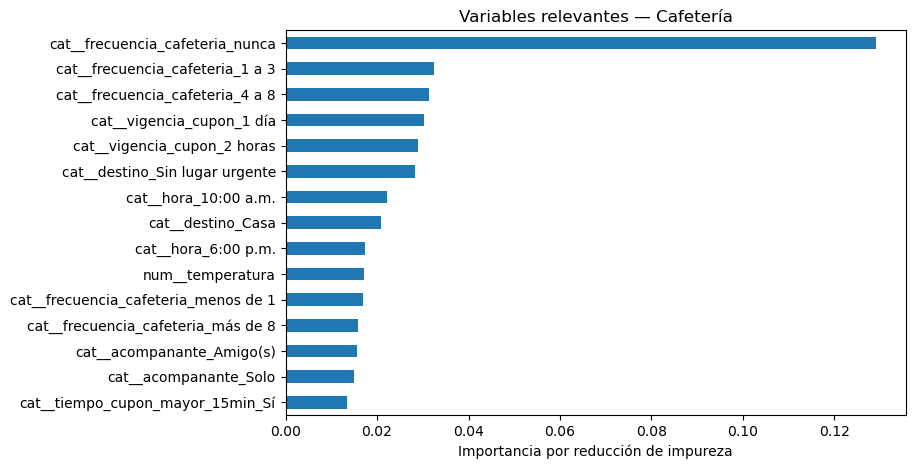

In [21]:
importancias = pd.Series(modelo_fit.feature_importances_, index=feature_names)
importancias = importancias.sort_values(ascending=False)
display(importancias.head(20))
importancias.head(15).sort_values().plot.barh(figsize=(8, 5))
plt.xlabel('Importancia por reducción de impureza')
plt.title(f'Variables relevantes — {CUPON}')
plt.show()


La categoria nunca de frecuencia_cafeteria tiene la mayor importancia individual: 12.91%. Sumando las categorias de cada variable original, frecuencia_cafeteria representa el 22.57%, ocupacion el 9.14%, ingreso el 6.44%, hora el 6.03%, vigencia_cupon el 5.93% y destino el 5.65%.

El bosque combina habitos, contexto y perfil del conductor. La relevancia de ocupacion debe interpretarse con cuidado: tiene muchas categorias y la importancia por impureza puede favorecer ese tipo de variable. Las importancias no expresan el sentido del efecto, no equivalen a causas y no demuestran que usar datos demograficos sea justo.


## 9. Guardar resultados

Persistimos el pipeline, como en la practica 7, y las metricas para integrar despues. Este modelo se ajusto solo en train. El ganador de cada cupon se reajustara con todos sus datos etiquetados al generar el CSV externo.


In [22]:
RUTA_RESULTADOS.mkdir(parents=True, exist_ok=True)
resultados.to_csv(RUTA_RESULTADOS / 'metricas_test.csv', index=False, encoding='utf-8-sig')
resultados_cv.to_csv(RUTA_RESULTADOS / 'cv_sin_balanceo.csv', index=False, encoding='utf-8-sig')
particion = pd.concat([
    pd.DataFrame({'id_fila': X_train.index, 'conjunto': 'train'}),
    pd.DataFrame({'id_fila': X_test.index, 'conjunto': 'test'}),
], ignore_index=True)
particion.to_csv(RUTA_RESULTADOS / 'particion.csv', index=False)
pd.DataFrame({'id_fila': X_test.index, 'real': y_test.to_numpy(), 'prediccion': y_pred}).to_csv(
    RUTA_RESULTADOS / 'predicciones_test_interno.csv', index=False
)
joblib.dump(mejor_modelo, RUTA_RESULTADOS / 'pipeline_evaluado.joblib')


['resultados\\cafeteria_bosque_aleatorio\\pipeline_evaluado.joblib']

In [23]:
importancias.rename('importancia').to_csv(RUTA_RESULTADOS / 'importancias.csv', encoding='utf-8-sig')


## 10. Analisis de resultados

**1. Caracteristicas relacionadas con la aceptacion**

La frecuencia de visitas concentra el 22.57% de la importancia agrupada del bosque. Tambien intervienen ocupacion, ingreso, hora, vigencia y destino. La importancia por impureza identifica dependencia predictiva, pero no indica el sentido de las asociaciones.

**2. Variables redundantes o poco informativas**

Se excluyeron la variable constante de tiempo mayor a 5 minutos y direccion_opuesta, que era el complemento de misma_direccion. vehiculo tenia cerca del 99.15% de faltantes. Las otras variables de tiempo expresan condiciones distintas y no se eliminaron solo por estar relacionadas. Una importancia pequena no basta para descartar un predictor sin una comparacion en validacion.

**3. Diferencias de desempeno**

Los tres modelos de Cafeteria usaron la misma particion. La comparacion registrada es:

| Modelo | F1 macro CV | Precision de aceptacion | Recall de aceptacion | F1 de aceptacion | F1 macro test |
|---|---:|---:|---:|---:|---:|
| Regresion logistica | 0.7193 | 0.6950 | 0.7406 | 0.7171 | 0.7083 |
| Arbol de decision | 0.7099 | 0.6837 | 0.7078 | 0.6955 | 0.6909 |
| Random Forest | 0.7482 | 0.7160 | 0.7431 | 0.7293 | 0.7248 |


Random Forest se selecciona para Cafeteria por su mayor F1 macro en validacion cruzada: 0.7482. Test confirma el orden observado, con 0.7248 para el bosque, 0.7083 para la regresion y 0.6909 para el arbol. La regresion ofrece una alternativa mas sencilla y tiene una brecha menor entre entrenamiento y test. El bosque presenta el mayor sobreajuste y la diferencia entre modelos no se ha sometido a una prueba de significancia.

Los notebooks de Restaurante aun no tienen resultados. No se puede afirmar cual cupon tiene mejor desempeno ni atribuir una diferencia a sus caracteristicas hasta evaluarlos.

**4. Balanceo en Restaurante**

Este notebook no evalua SMOTE y Cafeteria esta casi equilibrada. Todavia no hay resultados de Restaurante con y sin balanceo, por lo que no se puede recomendar la tecnica con evidencia. Esa conclusion requiere comparar el F1 macro, el F1 de aceptacion y el recall de la clase minoritaria en sus experimentos, con el test sin remuestrear.

**5. Reglas, utilidad y limitacion**

El arbol de Cafeteria predice aceptacion para visitas al menos mensuales, destino sin urgencia y vigencia de un dia. Predice rechazo para visitas al menos mensuales, destino casa o trabajo, establecimiento en otra direccion y vigencia de dos horas. Estas reglas explican decisiones concretas, pero no prueban causas ni garantizan aciertos en nuevos conductores. El bosque no tiene una unica regla equivalente para todas sus predicciones.

**6. Integracion en la aplicacion**

La aplicacion puede reunir las variables disponibles del trayecto y los habitos autorizados, aplicar el pipeline y estimar la probabilidad de aceptar cada oferta. Las oportunidades se pueden ordenar con esa estimacion, considerando cercania, vigencia y frecuencia de notificaciones. Debe evitarse distraer al conductor. El umbral de esta evaluacion es 0.5; cualquier cambio requiere validacion y no debe ajustarse con este test.

**7. Limitaciones de personalizar por perfil demografico**

El modelo puede tratar de manera distinta a personas por edad, genero, estado civil o ingreso, aunque sus necesidades individuales sean diferentes. Puede excluir ofertas utiles, repetir estereotipos y depender de datos privados o desactualizados. No se midieron los errores por grupo, asi que estas metricas globales no demuestran equidad. La probabilidad predicha tampoco garantiza una compra ni demuestra el efecto de enviar el cupon.

**8. Fuentes de sesgo e implicaciones**

La muestra puede representar de manera desigual a los conductores y las respuestas pueden reflejar sesgos previos. La imputacion por moda refuerza categorias frecuentes. La particion por filas no garantiza independencia entre conductores, porque id_fila no identifica personas. Ademas, otras variables pueden actuar como sustitutos del perfil demografico.

Antes de usarlo se deben revisar precision y recall por grupo junto con sus tamanos, proteger los datos personales y vigilar cambios en el comportamiento. Si se aplicara a precios dinamicos, estas diferencias podrian generar cobros desiguales; el desempeno obtenido para cupones no justifica trasladarlo directamente a ese uso.
